In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

train_df = pd.read_csv("/content/DailyDelhiClimateTrain.csv")
test_df = pd.read_csv("/content/DailyDelhiClimateTest.csv")

train_df["date"] = pd.to_datetime(train_df["date"])
test_df["date"] = pd.to_datetime(test_df["date"])

print(train_df.shape)
print(test_df.shape)
print(train_df.head())

(1462, 5)
(114, 5)
        date   meantemp   humidity  wind_speed  meanpressure
0 2013-01-01  10.000000  84.500000    0.000000   1015.666667
1 2013-01-02   7.400000  92.000000    2.980000   1017.800000
2 2013-01-03   7.166667  87.000000    4.633333   1018.666667
3 2013-01-04   8.666667  71.333333    1.233333   1017.166667
4 2013-01-05   6.000000  86.833333    3.700000   1016.500000


In [ ]:
# Remove duplicate dates
train_df = train_df.drop_duplicates(subset="date")
test_df = test_df.drop_duplicates(subset="date")

# Remove overlapping dates from test data
test_df = test_df[test_df["date"] > train_df["date"].max()]

# Replace invalid pressure values
train_df.loc[~train_df["meanpressure"].between(870, 1100), "meanpressure"] = np.nan
test_df.loc[~test_df["meanpressure"].between(870, 1100), "meanpressure"] = np.nan

# Fill missing values
features = ["meantemp", "humidity", "wind_speed", "meanpressure"]

train_df[features] = train_df[features].interpolate().ffill().bfill()
test_df[features] = test_df[features].interpolate().ffill().bfill()

print("Training records:", len(train_df))
print("Testing records:", len(test_df))
print("Missing values:\n", train_df[features].isnull().sum())

Training records: 1462
Testing records: 113
Missing values:
 meantemp        0
humidity        0
wind_speed      0
meanpressure    0
dtype: int64


In [ ]:
from sklearn.preprocessing import MinMaxScaler

features = ["meantemp", "humidity", "wind_speed", "meanpressure"]

scaler = MinMaxScaler()

train_scaled = scaler.fit_transform(train_df[features])
test_scaled = scaler.transform(test_df[features])

print("Training data shape:", train_scaled.shape)
print("Testing data shape:", test_scaled.shape)

Training data shape: (1462, 4)
Testing data shape: (113, 4)


In [ ]:
LOOKBACK = 30

def create_sequences(data, lookback):
    X, y = [], []

    for i in range(lookback, len(data)):
        X.append(data[i-lookback:i])
        y.append(data[i, 0])  # Next day's mean temperature

    return np.array(X), np.array(y)

X_train, y_train = create_sequences(train_scaled, LOOKBACK)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

X_train shape: (1432, 30, 4)
y_train shape: (1432,)


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

model = Sequential([
    LSTM(64, input_shape=(30, 4)),
    Dropout(0.2),
    Dense(32, activation="relu"),
    Dense(1)
])

model.compile(optimizer="adam", loss="mse")

model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.2,
    shuffle=False
)

Epoch 1/30


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - loss: 0.0840 - val_loss: 0.0151
Epoch 2/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0107 - val_loss: 0.0099
Epoch 3/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0109 - val_loss: 0.0089
Epoch 4/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0106 - val_loss: 0.0046
Epoch 5/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0080 - val_loss: 0.0054
Epoch 6/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0082 - val_loss: 0.0041
Epoch 7/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0086 - val_loss: 0.0042
Epoch 8/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0085 - val_loss: 0.0038
Epoch 9/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0088 - val_loss: 0.0041
Epoch 10/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0076 - val_loss: 0.0044
Epoch 11/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0070 - val_loss: 0.0046
Epoch 12/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0063 - val_l

In [ ]:
# Correctly reverse the scaling for meantemp
temp_index = features.index("meantemp")

predicted_temp = (
    pred_scaled.flatten()
    * (scaler.data_max_[temp_index] - scaler.data_min_[temp_index])
    + scaler.data_min_[temp_index]
)

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(actual_temp, predicted_temp)

rmse = np.sqrt(
    mean_squared_error(actual_temp, predicted_temp)
)

print("MAE:", round(mae, 3), "°C")
print("RMSE:", round(rmse, 3), "°C")

MAE: 1.82 °C
RMSE: 2.171 °C


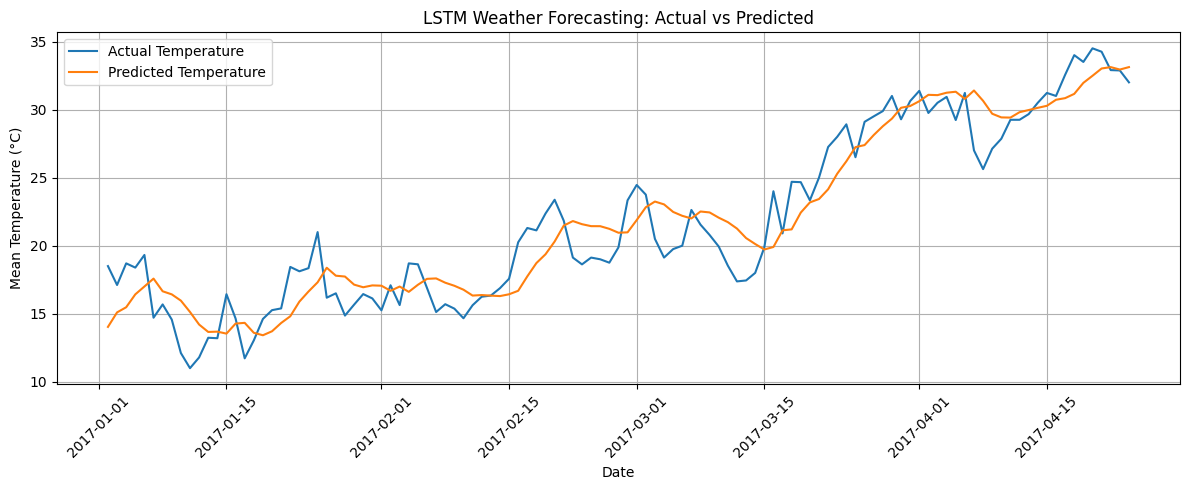

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    test_df["date"],
    actual_temp,
    label="Actual Temperature"
)

plt.plot(
    test_df["date"],
    predicted_temp,
    label="Predicted Temperature"
)

plt.xlabel("Date")
plt.ylabel("Mean Temperature (°C)")
plt.title("LSTM Weather Forecasting: Actual vs Predicted")
plt.legend()
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
results["Date"] = pd.to_datetime(results["Date"]).dt.strftime("%d-%m-%Y")

print(results.round(2))

         Date  Actual Temperature  Predicted Temperature
0  02-01-2017               18.50                  14.03
1  03-01-2017               17.11                  15.10
2  04-01-2017               18.70                  15.48
3  05-01-2017               18.39                  16.42
4  06-01-2017               19.32                  17.00


In [6]:
date_input = input("Enter date (YYYY-MM-DD): ")
date_input = pd.to_datetime(date_input)

result = test_df[test_df["date"] == date_input]

if not result.empty:
    index = result.index[0]
    position = test_df.index.get_loc(index)

    print("Actual Temperature:", actual_temp[position], "°C")
    print("Predicted Temperature:", round(predicted_temp[position], 2), "°C")
else:
    print("Date not found in test dataset.")

Enter date (YYYY-MM-DD): 06-01-2017
Date not found in test dataset.
